In [ ]:
import requests
import pandas as pd
import logging
import time
import requests
from typing import Optional, Tuple
from typing import Tuple, Dict, List
from typing import Union, List, Tuple
from concurrent.futures import ThreadPoolExecutor
import pickle
from collections import defaultdict
import numpy as np
from tqdm import tqdm
from pathlib import Path



def sign_in(username, password):
    s = requests.Session()
    s.auth = (username, password)
    try:
        response = s.post('https://api.worldquantbrain.com/authentication')
        response.raise_for_status()
        logging.info("Successfully signed in")
        return s
    except requests.exceptions.RequestException as e:
        logging.error(f"Login failed: {e}")
        return None

In [ ]:
def save_obj(obj: object, name: str) -> None:
    """
    保存对象到文件中，以 pickle 格式序列化。

    Args:
        obj (object): 需要保存的对象。
        name (str): 文件名（不包含扩展名），保存的文件将以 '.pickle' 为扩展名。

    Returns:
        None: 此函数无返回值。

    Raises:
        pickle.PickleError: 如果序列化过程中发生错误。
        IOError: 如果文件写入过程中发生 I/O 错误。
    """
    with open(name + '.pickle', 'wb') as f:
        pickle.dump(obj, f, pickle.HIGHEST_PROTOCOL)


def load_obj(name: str) -> object:
    """
    加载指定名称的 pickle 文件并返回其内容。

    此函数会打开一个以 `.pickle` 为扩展名的文件，并使用 `pickle` 模块加载其内容。

    Args:
        name (str): 不带扩展名的文件名称。

    Returns:
        object: 从 pickle 文件中加载的 Python 对象。

    Raises:
        FileNotFoundError: 如果指定的文件不存在。
        pickle.UnpicklingError: 如果文件内容无法被正确反序列化。
    """
    with open(name + '.pickle', 'rb') as f:
        return pickle.load(f)
    
def wait_get(url: str, max_retries: int = 10) -> "Response":
    """
    发送带有重试机制的 GET 请求，直到成功或达到最大重试次数。
    此函数会根据服务器返回的 `Retry-After` 头信息进行等待，并在遇到 401 状态码时重新初始化配置。
    
    Args:
        url (str): 目标 URL。
        max_retries (int, optional): 最大重试次数，默认为 10。
    
    Returns:
        Response: 请求的响应对象。
    """
    retries = 0
    while retries < max_retries:
        while True:
            simulation_progress = sess.get(url)
            if simulation_progress.headers.get("Retry-After", 0) == 0:
                break
            time.sleep(float(simulation_progress.headers["Retry-After"]))
        if simulation_progress.status_code < 400:
            break
        else:
            time.sleep(2 ** retries)
            retries += 1
    return simulation_progress

def _get_alpha_pnl(alpha_id: str) -> pd.DataFrame:
    """
    获取指定 alpha 的 PnL数据，并返回一个包含日期和 PnL 的 DataFrame。

    此函数通过调用 WorldQuant Brain API 获取指定 alpha 的 PnL 数据，
    并将其转换为 pandas DataFrame 格式，方便后续数据处理。

    Args:
        alpha_id (str): Alpha 的唯一标识符。

    Returns:
        pd.DataFrame: 包含日期和对应 PnL 数据的 DataFrame，列名为 'Date' 和 alpha_id。
    """
    pnl = wait_get("https://api.worldquantbrain.com/alphas/" + alpha_id + "/recordsets/pnl").json()
    df = pd.DataFrame(pnl['records'], columns=[item['name'] for item in pnl['schema']['properties']])
    df = df.rename(columns={'date':'Date', 'pnl':alpha_id})
    df = df[['Date', alpha_id]]
    return df

def get_alpha_pnls(
    alphas: list[dict], 
    alpha_pnls: Optional[pd.DataFrame] = None, 
    alpha_ids: Optional[dict[str, list]] = None
) -> Tuple[dict[str, list], pd.DataFrame]:
    """
    获取 alpha 的 PnL 数据，并按区域分类 alpha 的 ID。

    Args:
        alphas (list[dict]): 包含 alpha 信息的列表，每个元素是一个字典，包含 alpha 的 ID 和设置等信息。
        alpha_pnls (Optional[pd.DataFrame], 可选): 已有的 alpha PnL 数据，默认为空的 DataFrame。
        alpha_ids (Optional[dict[str, list]], 可选): 按区域分类的 alpha ID 字典，默认为空字典。

    Returns:
        Tuple[dict[str, list], pd.DataFrame]: 
            - 按区域分类的 alpha ID 字典。
            - 包含所有 alpha 的 PnL 数据的 DataFrame。
    """

    if alpha_ids is None:
        alpha_ids = defaultdict(list)
    if alpha_pnls is None:
        alpha_pnls = pd.DataFrame()
    
    new_alphas = [item for item in alphas if item['id'] not in alpha_pnls.columns]
    if not new_alphas:
        return alpha_ids, alpha_pnls
    
    for item_alpha in new_alphas:
        alpha_ids[item_alpha['settings']['region']].append(item_alpha['id'])


    fetch_pnl_func = lambda alpha_id: _get_alpha_pnl(alpha_id).set_index('Date')
    with ThreadPoolExecutor(max_workers=10) as executor:
        results = executor.map(fetch_pnl_func, [item['id'] for item in new_alphas])
    alpha_pnls = pd.concat([alpha_pnls] + list(results), axis=1)
    alpha_pnls.sort_index(inplace=True)

    return alpha_ids, alpha_pnls

def get_os_alphas(limit: int = 100, get_first: bool = False) -> List[Dict]:
    """
    获取OS阶段的alpha列表。

    此函数通过调用WorldQuant Brain API获取用户的alpha列表，支持分页获取，并可以选择只获取第一个结果。

    Args:
        limit (int, optional): 每次请求获取的alpha数量限制。默认为100。
        get_first (bool, optional): 是否只获取第一次请求的alpha结果。如果为True，则只请求一次。默认为False。

    Returns:
        List[Dict]: 包含alpha信息的字典列表，每个字典表示一个alpha。
    """
    fetched_alphas = []
    offset = 0
    retries = 0
    total_alphas = 100
    while len(fetched_alphas) < total_alphas:
        print(f"Fetching alphas from offset {offset} to {offset + limit}")
        url = f"https://api.worldquantbrain.com/users/self/alphas?stage=OS&limit={limit}&offset={offset}&order=-dateSubmitted"
        res = wait_get(url).json()
        if offset == 0:
            total_alphas = res['count']
        alphas = res["results"]
        fetched_alphas.extend(alphas)
        if len(alphas) < limit:
            break
        offset += limit
        if get_first:
            break
    return fetched_alphas[:total_alphas]



def calc_self_corr(
    alpha_id: str,
    os_alpha_rets: pd.DataFrame | None = None,
    os_alpha_ids: dict[str, str] | None = None,
    alpha_result: dict | None = None,
    return_alpha_pnls: bool = False,
    alpha_pnls: pd.DataFrame | None = None
) -> float | tuple[float, pd.DataFrame]:
    """
    计算指定 alpha 与其他 alpha 的最大自相关性。

    Args:
        alpha_id (str): 目标 alpha 的唯一标识符。
        os_alpha_rets (pd.DataFrame | None, optional): 其他 alpha 的收益率数据，默认为 None。
        os_alpha_ids (dict[str, str] | None, optional): 其他 alpha 的标识符映射，默认为 None。
        alpha_result (dict | None, optional): 目标 alpha 的详细信息，默认为 None。
        return_alpha_pnls (bool, optional): 是否返回 alpha 的 PnL 数据，默认为 False。
        alpha_pnls (pd.DataFrame | None, optional): 目标 alpha 的 PnL 数据，默认为 None。

    Returns:
        float | tuple[float, pd.DataFrame]: 如果 `return_alpha_pnls` 为 False，返回最大自相关性值；
            如果 `return_alpha_pnls` 为 True，返回包含最大自相关性值和 alpha PnL 数据的元组。
    """
    if alpha_result is None:
        alpha_result = wait_get(f"https://api.worldquantbrain.com/alphas/{alpha_id}").json()

    if alpha_pnls is not None:
        if len(alpha_pnls) == 0:
            alpha_pnls = None
    if alpha_pnls is None:
        _, alpha_pnls = get_alpha_pnls([alpha_result])
        alpha_pnls = alpha_pnls[alpha_id]

    alpha_rets = alpha_pnls - alpha_pnls.ffill().shift(1)

    alpha_rets = alpha_rets[pd.to_datetime(alpha_rets.index)>pd.to_datetime(alpha_rets.index).max() - pd.DateOffset(years=4)]


    # os_alpha_rets = os_alpha_rets.replace(0, np.nan)
    # alpha_rets = alpha_rets.replace(0, np.nan)
    print(os_alpha_rets[os_alpha_ids[alpha_result['settings']['region']]].corrwith(alpha_rets).sort_values(ascending=False).round(4))
    os_alpha_rets[os_alpha_ids[alpha_result['settings']['region']]].corrwith(alpha_rets).sort_values(ascending=False).round(4).to_csv(str(cfg.data_path / 'os_alpha_corr.csv'))
    self_corr = os_alpha_rets[os_alpha_ids[alpha_result['settings']['region']]].corrwith(alpha_rets).max()
    if np.isnan(self_corr):
        self_corr = 0
    if return_alpha_pnls:
        return self_corr, alpha_pnls
    else:
        return self_corr


def download_data(flag_increment=True):
    """
    下载数据并保存到指定路径。

    此函数会检查数据是否已经存在，如果不存在，则从 API 下载数据并保存到指定路径。

    Args:
        flag_increment (bool): 是否使用增量下载，默认为 True。
    """
    if flag_increment:
        try:
            os_alpha_ids = load_obj(str(cfg.data_path / 'os_alpha_ids'))
            os_alpha_pnls = load_obj(str(cfg.data_path / 'os_alpha_pnls'))
            ppac_alpha_ids = load_obj(str(cfg.data_path / 'ppac_alpha_ids'))
            exist_alpha = [alpha for ids in os_alpha_ids.values() for alpha in ids]
        except Exception as e:
            logging.error(f"Failed to load existing data: {e}")
            os_alpha_ids = None
            os_alpha_pnls = None
            exist_alpha = []
            ppac_alpha_ids = []
    else:
        os_alpha_ids = None
        os_alpha_pnls = None
        exist_alpha = []
        ppac_alpha_ids = []
        
    if os_alpha_ids is None:
        alphas = get_os_alphas(limit=100, get_first=False)
    else:
        alphas = get_os_alphas(limit=30, get_first=True)

    
    alphas = [item for item in alphas if item['id'] not in exist_alpha]

    ppac_alpha_ids += [item['id'] for item in alphas for item_match in item['classifications'] if item_match['name'] == 'Power Pool Alpha']
            
    os_alpha_ids, os_alpha_pnls = get_alpha_pnls(alphas, alpha_pnls=os_alpha_pnls, alpha_ids=os_alpha_ids)
    save_obj(os_alpha_ids, str(cfg.data_path / 'os_alpha_ids'))
    save_obj(os_alpha_pnls, str(cfg.data_path / 'os_alpha_pnls'))
    save_obj(ppac_alpha_ids, str(cfg.data_path / 'ppac_alpha_ids'))
    print(f'新下载的alpha数量: {len(alphas)}, 目前总共alpha数量: {os_alpha_pnls.shape[1]}')

def load_data(tag=None):
    """
    加载数据。

    此函数会检查数据是否已经存在，如果不存在，则从 API 下载数据并保存到指定路径。

    Args:
        tag (str): 数据标记，默认为 None。
    """
    os_alpha_ids = load_obj(str(cfg.data_path / 'os_alpha_ids'))
    os_alpha_pnls = load_obj(str(cfg.data_path / 'os_alpha_pnls'))
    ppac_alpha_ids = load_obj(str(cfg.data_path / 'ppac_alpha_ids'))


    if tag=='PPAC':
        for item in os_alpha_ids:
            os_alpha_ids[item] = [alpha for alpha in os_alpha_ids[item] if alpha in ppac_alpha_ids]
    elif tag=='SelfCorr':
        for item in os_alpha_ids:
            os_alpha_ids[item] = [alpha for alpha in os_alpha_ids[item] if alpha not in ppac_alpha_ids]
    else:
        os_alpha_ids = os_alpha_ids

    exist_alpha = [alpha for ids in os_alpha_ids.values() for alpha in ids]
    os_alpha_pnls = os_alpha_pnls[exist_alpha]

    os_alpha_rets = os_alpha_pnls - os_alpha_pnls.ffill().shift(1)
    os_alpha_rets = os_alpha_rets[pd.to_datetime(os_alpha_rets.index)>pd.to_datetime(os_alpha_rets.index).max() - pd.DateOffset(years=4)]
    return os_alpha_ids, os_alpha_rets

In [ ]:
from os.path import expanduser
import json

class cfg:
    # 使用示例
    with open(expanduser('brain.json')) as f:

        credentials = json.load(f)

    # Extract username and password from the list
    username, password = credentials.get('vincent')
    
    data_path = Path('.')

In [ ]:
# 登录
sess = sign_in(cfg.username, cfg.password)

In [ ]:
# 增量下载数据
download_data(flag_increment=True)

In [ ]:
# 加载数据， 如果需要使用不同的标签，可以传入 tag 参数， 例如 tag='PPAC' 或 tag='SelfCorr'
# os_alpha_ids, os_alpha_rets = load_data(tag='PPAC')

- 厂型因子

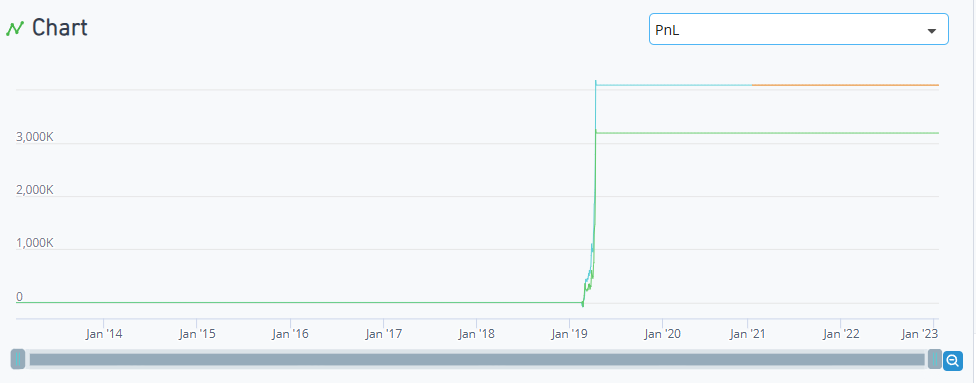

Self Correlation

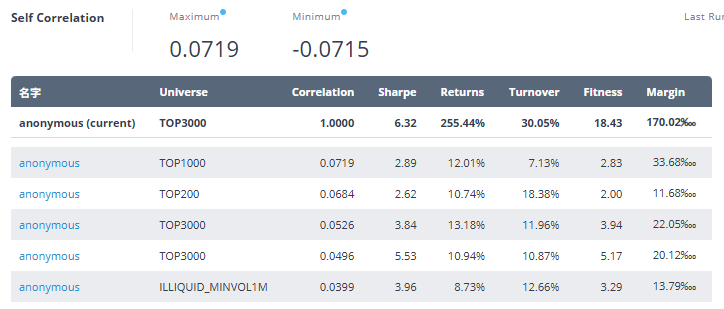

PPAC Correlation
- Power Pool correlation 0.0356 is below cutoff of 0.5, or Sharpe is better by 10.0% or more.

In [ ]:
alpha_id = 'KoLz1dE'
os_alpha_ids, os_alpha_rets = load_data(tag='SelfCorr')
calc_self_corr(
    alpha_id=alpha_id,
    os_alpha_rets=os_alpha_rets,
    os_alpha_ids=os_alpha_ids,
)

In [ ]:
alpha_id = 'OLoaA0p'

os_alpha_ids, os_alpha_rets = load_data(tag='PPAC')

result = calc_self_corr(
    alpha_id=alpha_id,
    os_alpha_rets=os_alpha_rets,
    os_alpha_ids=os_alpha_ids,
)



- 正常因子

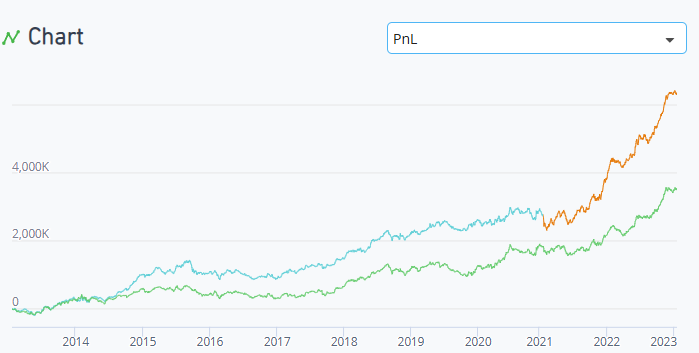

Self Correlation

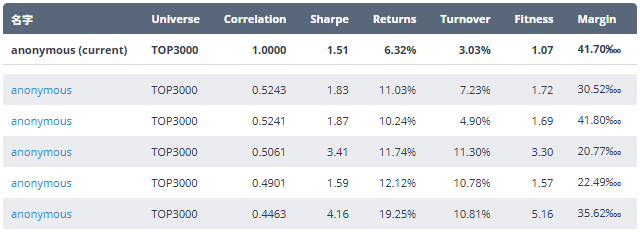

PPAC Correlation
- Power Pool correlation 0.4901 is below cutoff of 0.5, or Sharpe is better by 10.0% or more.


In [ ]:
alpha_id = 'JPY3x52'
os_alpha_ids, os_alpha_rets = load_data(tag='SelfCorr')
calc_self_corr(
    alpha_id=alpha_id,
    os_alpha_rets=os_alpha_rets,
    os_alpha_ids=os_alpha_ids,
)

In [6]:
df = pd.read_csv('20250922105242.csv')
alpha_id_list = df['id'].tolist()


os_alpha_ids, os_alpha_rets = load_data(tag='PPAC')

for alpha_id in tqdm(alpha_id_list):
    
    PPAC_SELF_CORR = calc_self_corr(
        alpha_id=alpha_id,
        os_alpha_rets=os_alpha_rets,
        os_alpha_ids=os_alpha_ids,
    )

    print(f'当前alpha_id: {alpha_id}, 自相关系数: {PPAC_SELF_CORR}')
    # 记录结果
    df.loc[df['id'] == alpha_id, 'PPAC_SELF_CORR'] = PPAC_SELF_CORR

# 按PPAC_SELF_CORR排序
df = df.sort_values(by='PPAC_SELF_CORR', ascending=False)

# 保留PPAC_SELF_CORR小于0.5的
df = df[df['PPAC_SELF_CORR'] < 0.5]

# 输出
df.to_csv('9.22_PPAC_SELF_CORR.csv', index=False)

 10%|▉         | 33/334 [02:32<18:48,  3.75s/it]

LQ82ARa    0.9392
KoLz1dE    0.1417
2gwYQN5    0.0661
K1vzxGx    0.0624
EMV7lxJ    0.0423
13Eo2ZJ    0.0232
OXQkvzY    0.0115
OdA2vjd    0.0005
zLkeRQ1   -0.0054
Exnelar   -0.0103
XxO9oVx   -0.0213
0V1E1qk   -0.0458
raE1JXJ   -0.0613
XM309dX   -0.0727
dtype: float64
当前alpha_id: NZK2XX8, 自相关系数: 0.9391538818811568


 10%|▉         | 33/334 [02:37<23:54,  4.77s/it]


KeyboardInterrupt: 